In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
pd.set_option('display.max_rows',None)
pd.set_option('display.max_columns',None)

## load dataset:

In [3]:
load=pd.read_csv('repair_cost.csv')

In [4]:
titles=load.columns

In [5]:
titles

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [6]:
load.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [7]:
load.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [8]:
load['failure_flag']=load[['Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF']].max(axis=1)

In [9]:
load.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,failure_flag
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,0


In [10]:
# load.iloc[500:600,8:15]

In [11]:
load.drop(['Product ID','Machine failure'],axis=1,inplace=True)

In [12]:
load.drop(['TWF','HDF','PWF','OSF','RNF'],axis=1,inplace=True)

In [13]:
load.drop('UDI',axis=1,inplace=True)


In [14]:
load=pd.get_dummies(load,drop_first=True).astype(int)

In [15]:
load.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],failure_flag,Type_L,Type_M
0,298,308,1551,42,0,0,0,1
1,298,308,1408,46,3,0,1,0
2,298,308,1498,49,5,0,1,0
3,298,308,1433,39,7,0,1,0
4,298,308,1408,40,9,0,1,0


______________________________________________________________________________________________________________________________________________

## model creation and DS concepts:

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

In [17]:
x=load.drop('failure_flag',axis=1)
y=load['failure_flag']

In [18]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,train_size=0.75,random_state=42)

In [19]:
rf=RandomForestClassifier()

In [33]:
model_pred=rf.fit(xtrain,ytrain).predict(xtest)

In [20]:
from sklearn.metrics import classification_report,confusion_matrix

In [34]:
cm=confusion_matrix(ytest,model_pred)

### model accuracy:

In [35]:
cm


array([[2414,    8],
       [  36,   42]])

In [36]:
cls=classification_report(ytest,ypred)

In [37]:
print(cls)


              precision    recall  f1-score   support

           0       0.98      0.99      0.99      2422
           1       0.69      0.47      0.56        78

    accuracy                           0.98      2500
   macro avg       0.83      0.73      0.77      2500
weighted avg       0.97      0.98      0.97      2500



In [ ]:
______________________________________________________________________________________________________________________________________________

In [ ]:
______________________________________________________________________________________________________________________________________________

In [23]:
data=load['failure_flag'].value_counts()

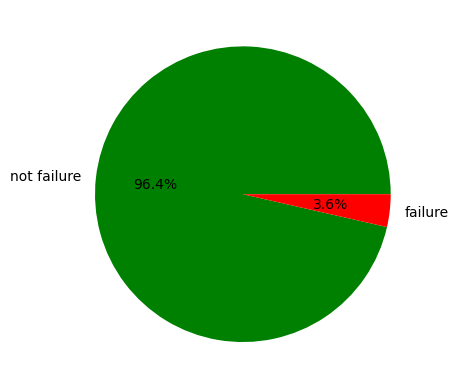

In [24]:
plt.pie(data.values,labels=['not failure','failure'],autopct="%1.1f%%",colors=['green','red'])
plt.show()

______________________________________________________________________________________________________________________________________________

# handle imbalanced data:


## undersampling:


In [79]:
# plz  skip this part ,because is not best accuracy..

In [24]:
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import confusion_matrix,classification_report 

In [21]:
under=RandomUnderSampler()
x_re,y_re=under.fit_resample(xtrain,ytrain)

In [22]:
rf=RandomForestClassifier()
ypred=rf.fit(x_re,y_re).predict(xtest)

## undersample accuracy:

In [25]:
cm=confusion_matrix(ytest,ypred)
cm

array([[2157,  265],
       [  10,   68]])

In [26]:
cls=classification_report(ytest,ypred)
print(cls)

              precision    recall  f1-score   support

           0       1.00      0.89      0.94      2422
           1       0.20      0.87      0.33        78

    accuracy                           0.89      2500
   macro avg       0.60      0.88      0.64      2500
weighted avg       0.97      0.89      0.92      2500



-----------------------------------------------------------------------------------------------------------------------
-----------------------------------------------------------------------------------------------------------------------

## over sampling:

In [27]:
from imblearn.over_sampling import RandomOverSampler

In [28]:
over=RandomOverSampler()

In [29]:
x_re,y_re=over.fit_resample(xtrain,ytrain)

In [30]:
rf=RandomForestClassifier()
ypred=rf.fit(x_re,y_re).predict(xtest)

## oversample accuracy:

In [31]:
cm=confusion_matrix(ytest,ypred)
cm

array([[2405,   17],
       [  41,   37]])

In [32]:
cls=classification_report(ytest,ypred)
print(cls)

              precision    recall  f1-score   support

           0       0.98      0.99      0.99      2422
           1       0.69      0.47      0.56        78

    accuracy                           0.98      2500
   macro avg       0.83      0.73      0.77      2500
weighted avg       0.97      0.98      0.97      2500



------------------------------------------------------------------------------------------------------------------------
------------------------------------------------------------------------------------------------------------------------